In [1]:
# import packages
from scipy.stats import norm
from scipy.stats import chi2
from scipy.special import logit, expit
from statsmodels.api import MNLogit
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families import Poisson
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patsy
import os
from itertools import product
pd.set_option("display.width", 2000)

# import custom functions
from ST5213_helpers import *

In [2]:
df = pd.DataFrame(list(product([17, 22, 27, 32, 37, 42, 47], ['N', 'S', 'O'])), 
                  columns=['A', 'C'])
df['Count'] = [232, 3, 61, 400, 80, 137,
               301, 216, 131, 203, 268, 76,
               188, 197, 50, 164, 150, 24,
               183, 91, 10]

df1 = df.copy()
df1['A'] = pd.Categorical(df1['A'])
df1['C'] = pd.Categorical(df1['C'], categories=['N', 'S', 'O'], ordered=True)
df1.head()

,A,C,Count
0,17,N,232
1,17,S,3
2,17,O,61
3,22,N,400
4,22,S,80


In [3]:
df1_long = df1.loc[df1.index.repeat(df1['Count'])].reset_index(drop=True)
df1_long = df1_long.drop(columns=['Count'])
print(df1_long.head())

    A  C
0  17  N
1  17  N
2  17  N
3  17  N
4  17  N


In [4]:
y = df1_long['C'].cat.codes
X = patsy.dmatrix('A', df1_long, return_type='dataframe')

fm = MNLogit(y, X).fit()
print(fm.summary2())

Optimization terminated successfully.
         Current function value: 0.907709
         Iterations 8
                         Results: MNLogit
Model:              MNLogit          Method:           MLE        
Dependent Variable: y                Pseudo R-squared: 0.083      
Date:               2026-10-28 17:45 AIC:              5773.7982  
No. Observations:   3165             BIC:              5858.6369  
Df Model:           12               Log-Likelihood:   -2872.9    
Df Residuals:       3151             LL-Null:          -3133.5    
Converged:          1.0000           LLR p-value:      7.1230e-104
No. Iterations:     8.0000           Scale:            1.0000     
------------------------------------------------------------------
   y = 0       Coef.   Std.Err.     t     P>|t|    [0.025   0.975]
------------------------------------------------------------------
Intercept     -4.3481    0.5811  -7.4829  0.0000  -5.4870  -3.2092
  A[T.22]      2.7387    0.5938   4.6118  0.0000   1

In [5]:
print(fm.params.round(3), '\n')
beta = np.array(fm.params)
print(np.round(np.exp(beta), 3), "\n")

               0      1
Intercept -4.348 -1.336
A[T.22]    2.739  0.264
A[T.27]    4.016  0.504
A[T.32]    4.626  0.353
A[T.37]    4.395  0.011
A[T.42]    4.259 -0.586
A[T.47]    3.649 -1.571 

[[1.30000e-02 2.63000e-01]
 [1.54670e+01 1.30300e+00]
 [5.54950e+01 1.65500e+00]
 [1.02095e+02 1.42400e+00]
 [8.10350e+01 1.01200e+00]
 [7.07320e+01 5.57000e-01]
 [3.84550e+01 2.08000e-01]] 



In [6]:
df2 = df.copy()
df2['A'] = (df2['A'] - 32) / 5
df2['C'] = pd.Categorical(df2['C'], categories=['N', 'S', 'O'], ordered=True)
df2.head()

,A,C,Count
0,-3.0,N,232
1,-3.0,S,3
2,-3.0,O,61
3,-2.0,N,400
4,-2.0,S,80


In [7]:
df2['A2'] = df2['A']**2
df2['A3'] = df2['A']**3
df2['A4'] = df2['A']**4

In [8]:
df2_long = df2.loc[df2.index.repeat(df2['Count'])].reset_index(drop=True)
df2_long = df2_long.drop(columns=['Count'])
print(df2_long.head())

     A  C   A2    A3    A4
0 -3.0  N  9.0 -27.0  81.0
1 -3.0  N  9.0 -27.0  81.0
2 -3.0  N  9.0 -27.0  81.0
3 -3.0  N  9.0 -27.0  81.0
4 -3.0  N  9.0 -27.0  81.0


In [9]:
y = df2_long['C'].cat.codes
X = patsy.dmatrix('A+A2+A3+A4', df2_long, return_type='dataframe')

fm1 = MNLogit(y, X.iloc[:, :2]).fit()
fm2 = MNLogit(y, X.iloc[:, :3]).fit()
fm3 = MNLogit(y, X.iloc[:, :4]).fit()
fm4 = MNLogit(y, X).fit()

Optimization terminated successfully.
         Current function value: 0.954151
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.910944
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.908414
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.908319
         Iterations 7


In [10]:
print(anova_nested(fm1, fm2, fm3, fm4))

         Resid. Df   Resid. Dev   Df    Deviance      Pr(>Chi)
Model 1     3161.0  6039.775859  NaN         NaN           NaN
Model 2     3159.0  5766.272778  2.0  273.503081  4.069683e-60
Model 3     3157.0  5750.260204  2.0   16.012574  3.333602e-04
Model 4     3155.0  5749.661245  2.0    0.598959  7.412041e-01


In [11]:
print(anova_nested(fm3, fm))

         Resid. Df   Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1     3157.0  5750.260204  NaN       NaN       NaN
Model 2     3151.0  5745.798207  6.0  4.461997  0.614414


In [12]:
print(fm3.aic, fm.aic)
print(fm3.llf, fm.llf)

5766.260203998094 5773.798206892237
-2875.130101999047 -2872.8991034461187


In [13]:
fm0 = MNLogit(y, X.iloc[:, 0]).fit()
print(anova_nested(fm0, fm3))

Optimization terminated successfully.
         Current function value: 0.990032
         Iterations 5
         Resid. Df   Resid. Dev   Df    Deviance       Pr(>Chi)
Model 1     3163.0  6266.900873  NaN         NaN            NaN
Model 2     3157.0  5750.260204  6.0  516.640669  2.185514e-108


In [14]:
print(fm3.summary2())

                         Results: MNLogit
Model:              MNLogit          Method:           MLE        
Dependent Variable: y                Pseudo R-squared: 0.082      
Date:               2026-10-28 17:48 AIC:              5766.2602  
No. Observations:   3165             BIC:              5814.7395  
Df Model:           6                Log-Likelihood:   -2875.1    
Df Residuals:       3157             LL-Null:          -3133.5    
Converged:          1.0000           LLR p-value:      2.1855e-108
No. Iterations:     7.0000           Scale:            1.0000     
------------------------------------------------------------------
   y = 0      Coef.   Std.Err.     t      P>|t|    [0.025   0.975]
------------------------------------------------------------------
Intercept     0.2164    0.0602    3.5957  0.0003   0.0985   0.3344
        A     0.1998    0.0584    3.4224  0.0006   0.0854   0.3142
       A2    -0.2855    0.0214  -13.3237  0.0000  -0.3275  -0.2435
       A3     0.0405

In [23]:
counts = df2.pivot(index='A', columns='C', values='Count')
counts = counts.reindex(columns=['N', 'S', 'O'], fill_value=0)

obs_log_odds = pd.DataFrame({
    'S': np.log(counts['S'] / counts['N']),
    'O': np.log(counts['O'] / counts['N'])
})

A_grid = np.linspace(df2['A'].min(), df2['A'].max(), 200)

X_grid = pd.DataFrame({
    'Intercept': 1.0,
    'A': A_grid,
    'A2': A_grid**2,
    'A3': A_grid**3
})

pred = fm3.predict(X_grid)
pred.columns = ['N', 'S', 'O']  # Verify category encoding

fit_log_odds = pd.DataFrame({
    'S': np.log(pred['S'] / pred['N']),
    'O': np.log(pred['O'] / pred['N'])
})


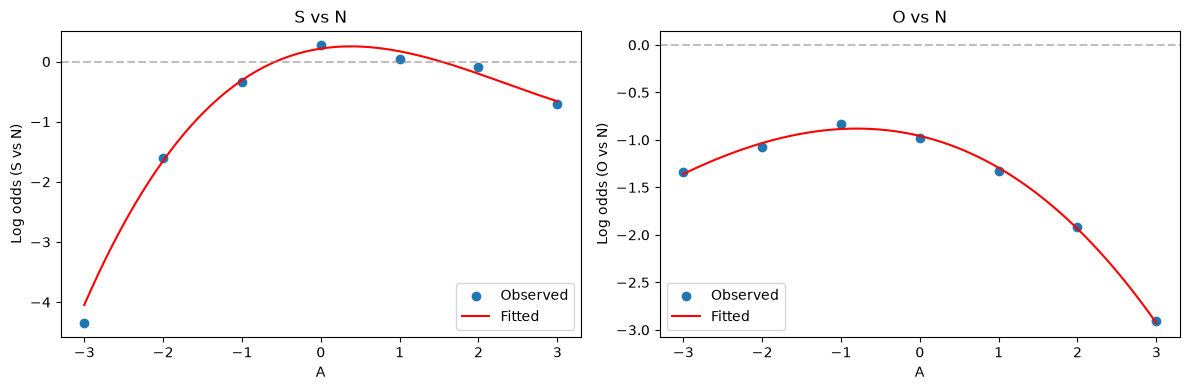

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, category in zip(axes, ['S', 'O']):
    ax.scatter(
        obs_log_odds.index,
        obs_log_odds[category],
        label='Observed'
    )

    ax.plot(
        A_grid,
        fit_log_odds[category],
        color='red',
        label='Fitted'
    )

    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_xlabel('A')
    ax.set_ylabel(f'Log odds ({category} vs N)')
    ax.set_title(f'{category} vs N')
    ax.legend()

plt.tight_layout()
plt.show()

In [25]:
A = (40 - 32) / 5

X_new = pd.DataFrame({
    'Intercept': [1.0],
    'A': [A],
    'A2': [A**2],
    'A3': [A**3]
})

pred40 = fm3.predict(X_new)
pred40.columns = ['N', 'S', 'O']  # Assuming this category order

pred40['S'].iloc[0] / pred40['O'].iloc[0]

np.float64(5.006367066975126)

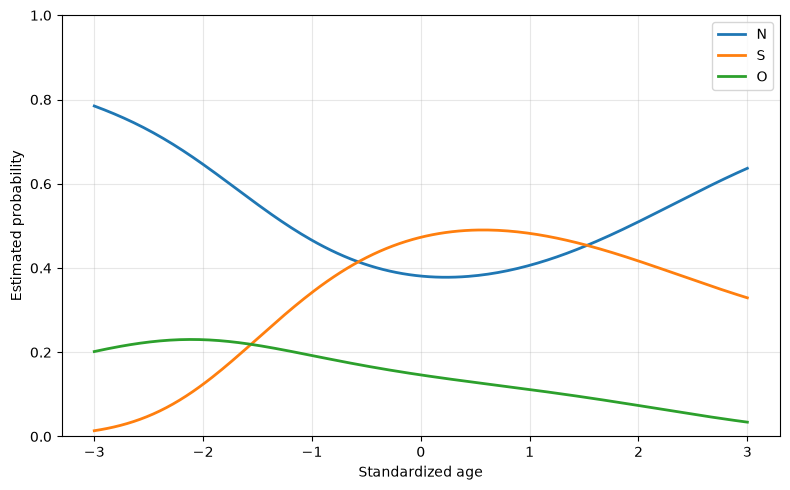

In [26]:
plt.figure(figsize=(8, 5))

for category in ['N', 'S', 'O']:
    plt.plot(
        A_grid,
        pred[category],
        linewidth=2,
        label=category
    )

plt.xlabel('Standardized age')
plt.ylabel('Estimated probability')
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
df_new = pd.DataFrame({
    'A': [17, 22, 27, 32, 37, 42, 47],
    'N': [232, 400, 301, 203, 188, 164, 183],
    'S': [3, 80, 216, 268, 197, 150, 91],
    'O': [61, 137, 131, 76, 50, 24, 10]
})

df_new1 = df_new.copy()
df_new1['A'] = pd.Categorical(df_new1['A'])
df_new1['Method'] = df_new1['S'] + df_new1['O']

fm = glm('Method + N ~ A', df_new1, family=Binomial()).fit()
drop1_glm(fm)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,2.220446e-14,58.950914,,
A,6,2.188388e+02,265.789732,218.838818,0.0


In [15]:
df_new2 = df_new.copy()
df_new2['A'] = (df_new2['A'] - 32) / 5
df_new2['Method'] = df_new2['S'] + df_new2['O']

fm1 = glm('Method + N ~ A', df_new2, family=Binomial()).fit()
drop1_glm(fm1)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,180.854641,229.805555,,
A,1,218.838818,265.789732,37.984177,0.0


In [16]:
fm2 = update_glm(fm1, add='I(A**2)')
print(anova_nested(fm1, fm2))

         Resid. Df  Resid. Dev   Df    Deviance      Pr(>Chi)
Model 1        5.0  180.854641  NaN         NaN           NaN
Model 2        4.0    6.119465  1.0  174.735175  6.839712e-40


In [17]:
fm3 = update_glm(fm2, add='I(A**3)')
print(anova_nested(fm1, fm2, fm3))

         Resid. Df  Resid. Dev   Df    Deviance      Pr(>Chi)
Model 1        5.0  180.854641  NaN         NaN           NaN
Model 2        4.0    6.119465  1.0  174.735175  6.839712e-40
Model 3        3.0    6.041849  1.0    0.077617  7.805534e-01


In [18]:
print(anova_nested(fm2, fm))

         Resid. Df    Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1        4.0  6.119465e+00  NaN       NaN       NaN
Model 2        0.0  2.220446e-14  4.0  6.119465  0.190402


In [19]:
chi2.sf(fm2.deviance, fm2.df_resid)

np.float64(0.1904024017122776)

In [20]:
fm = glm('S + O ~ A', df_new1, family=Binomial()).fit()
drop1_glm(fm)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,8.903989e-14,49.323233,,
A,6,3.022638e+02,339.587081,302.263849,0.0


In [21]:
fm1 = glm('S + O ~ A', df_new2, family=Binomial()).fit()
drop1_glm(fm1)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,41.614906,80.938139,,
A,1,302.263849,339.587081,260.648943,0.0


In [22]:
fm2 = update_glm(fm1, add='I(A**2)')
print(anova_nested(fm1, fm2))

         Resid. Df  Resid. Dev   Df  Deviance      Pr(>Chi)
Model 1        5.0   41.614906  NaN       NaN           NaN
Model 2        4.0   10.773516  1.0  30.84139  2.800016e-08


In [23]:
fm3 = update_glm(fm2, add='I(A**3)')
print(anova_nested(fm1, fm2, fm3))

         Resid. Df  Resid. Dev   Df   Deviance      Pr(>Chi)
Model 1        5.0   41.614906  NaN        NaN           NaN
Model 2        4.0   10.773516  1.0  30.841390  2.800016e-08
Model 3        3.0    2.129860  1.0   8.643656  3.282022e-03


In [25]:
fm4 = update_glm(fm3, add='I(A**4)')
print(anova_nested(fm1, fm2, fm3, fm4))

         Resid. Df  Resid. Dev   Df   Deviance      Pr(>Chi)
Model 1        5.0   41.614906  NaN        NaN           NaN
Model 2        4.0   10.773516  1.0  30.841390  2.800016e-08
Model 3        3.0    2.129860  1.0   8.643656  3.282022e-03
Model 4        2.0    1.935556  1.0   0.194303  6.593591e-01


In [26]:
print(anova_nested(fm3, fm))

         Resid. Df    Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1        3.0  2.129860e+00  NaN       NaN       NaN
Model 2        0.0  8.903989e-14  3.0   2.12986  0.545896


In [27]:
chi2.sf(fm3.deviance, fm3.df_resid)

np.float64(0.5458956311816272)